# Nexar Collision Prediction — Baselines and Evaluation

**Computer Vision Project**

## Goal

This notebook establishes the baseline and evaluation framework for the
collision-prediction experiments.

The notebook has four main purposes:

1. Create a reproducible temporal sampling index.
2. Establish a naive baseline.
3. Establish a classical optical-flow baseline.
4. Define the evaluation procedure that will later be used by the
   learned temporal model.

The main experimental conditions are:

- TTE = 0.5 seconds
- TTE = 1.0 seconds
- TTE = 1.5 seconds

The observation window is:

- 2 seconds

Each clip is represented using:

- 16 sampled frames

The same validation videos and temporal sampling protocol must be used
when comparing the different models.

No frames after the prediction time are allowed into a clip.

## 1. Imports

We use:

- `pandas` for metadata and experiment tables
- `numpy` for numerical operations
- `matplotlib` for visualisation
- `cv2` for video processing and optical flow
- `Path` for file paths
- `scikit-learn` for classification and evaluation

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Experiment configuration

We define the important experimental parameters in one place.

This prevents different parts of the notebook from accidentally using
different settings.

In [2]:
DATA_DIR = Path("./data/raw")
PROCESSED_DIR = Path("./data/processed")
RESULTS_DIR = Path("./results")

TRAIN_DIR = DATA_DIR / "train"

TTE_VALUES = [0.5, 1.0, 1.5]

CLIP_DURATION = 2.0
NUM_FRAMES = 16

RANDOM_SEED = 42

print("TTE values:", TTE_VALUES)
print("Clip duration:", CLIP_DURATION)
print("Number of frames:", NUM_FRAMES)
print("Random seed:", RANDOM_SEED)

TTE values: [0.5, 1.0, 1.5]
Clip duration: 2.0
Number of frames: 16
Random seed: 42


## 3. Load the fixed train/validation split

Notebook 3 created the train/validation split.

We must use those saved files rather than generating a new split.

This ensures that every model is evaluated on the same videos.

In [3]:
train_df = pd.read_csv(
    PROCESSED_DIR / "train_split.csv"
)

val_df = pd.read_csv(
    PROCESSED_DIR / "val_split.csv"
)

print("Training videos:", len(train_df))
print("Validation videos:", len(val_df))

Training videos: 1200
Validation videos: 300


In [4]:
print("Training class distribution:")
print(train_df["target"].value_counts())

print("\nValidation class distribution:")
print(val_df["target"].value_counts())

Training class distribution:
target
1    600
0    600
Name: count, dtype: int64

Validation class distribution:
target
0    150
1    150
Name: count, dtype: int64


## 4. Verify that the saved split is still leakage-free

In [5]:
train_ids = set(train_df["id"])
val_ids = set(val_df["id"])

overlap = train_ids.intersection(val_ids)

print("Number of overlapping video IDs:", len(overlap))

if len(overlap) == 0:
    print("No train/validation video overlap.")
else:
    print("WARNING: overlap detected.")

Number of overlapping video IDs: 0
No train/validation video overlap.


# Part A — Reproducible Negative Sampling

Positive videos have an annotated event.

Negative videos do not.

For a positive video:

`prediction_time = event_time - TTE`

For a negative video, there is no event from which to calculate a
prediction time.

We therefore need a reproducible negative sampling strategy.

Rather than selecting completely arbitrary timestamps, we approximately
match the distribution of positive prediction times.

This reduces the possibility that a classifier learns an accidental
relationship between the time position within a video and the class
label.

## 5. Positive prediction-time distribution

For each TTE, we calculate the prediction time of every valid positive
training example.

For example:

`prediction_time = event_time - 1.0`

when TTE = 1.0 seconds.

These prediction times will provide the reference distribution for
negative sampling.

In [6]:
positive_train = train_df[
    train_df["target"] == 1
].copy()

positive_val = val_df[
    val_df["target"] == 1
].copy()

print("Positive training videos:", len(positive_train))
print("Positive validation videos:", len(positive_val))

Positive training videos: 600
Positive validation videos: 150


In [7]:
positive_prediction_times = {}

for tte in TTE_VALUES:
    prediction_times = (
        positive_train["time_of_event"] - tte
    )
    
    valid_times = prediction_times[
        prediction_times >= CLIP_DURATION
    ]
    
    positive_prediction_times[tte] = valid_times.to_numpy()
    
    print(
        f"TTE = {tte:.1f}s -> "
        f"{len(valid_times)} valid positive prediction times"
    )

TTE = 0.5s -> 600 valid positive prediction times
TTE = 1.0s -> 600 valid positive prediction times
TTE = 1.5s -> 599 valid positive prediction times


## 6. Visualise positive prediction-time distributions

Before using these distributions for negative sampling, we inspect
them.

The x-axis represents the location of the prediction point within the
video.

The distribution is different for each TTE because subtracting a
different TTE shifts the prediction time.

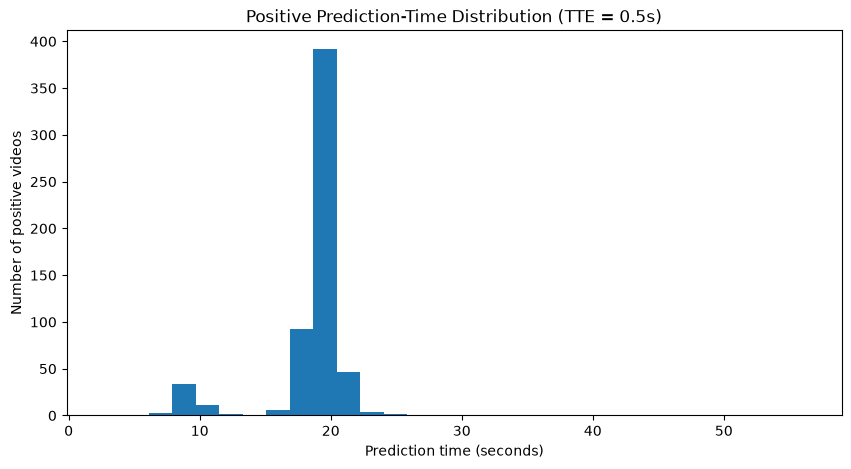

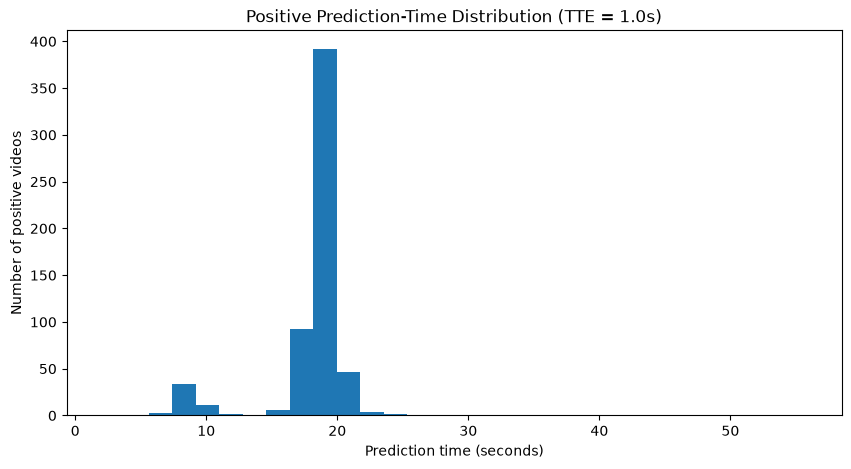

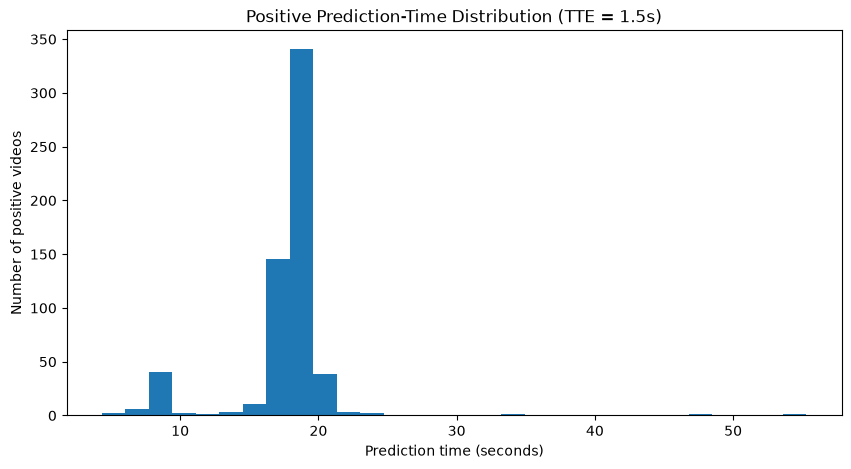

In [8]:
for tte in TTE_VALUES:
    plt.figure(figsize=(10, 5))
    
    plt.hist(
        positive_prediction_times[tte],
        bins=30
    )
    
    plt.xlabel("Prediction time (seconds)")
    plt.ylabel("Number of positive videos")
    plt.title(
        f"Positive Prediction-Time Distribution "
        f"(TTE = {tte:.1f}s)"
    )
    
    plt.show()

## 7. Negative prediction-time sampler

For every negative video, we choose a prediction time from the
corresponding positive prediction-time distribution.

The chosen time must satisfy:

`prediction_time >= CLIP_DURATION`

and:

`prediction_time <= video_duration`

A fixed random seed is used.

This means the negative sampling procedure can be reproduced.

In [9]:
def get_video_duration(video_path):
    cap = cv2.VideoCapture(str(video_path))
    
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )
    
    cap.release()
    
    if fps <= 0:
        return None
    
    return frame_count / fps

## 8. Test the duration function

In [10]:
test_negative_id = int(
    train_df[train_df["target"] == 0].iloc[0]["id"]
)

test_negative_path = (
    TRAIN_DIR / f"{test_negative_id:05d}.mp4"
)

test_duration = get_video_duration(
    test_negative_path
)

print("Video ID:", test_negative_id)
print("Duration:", test_duration)

Video ID: 1888
Duration: 40.1


## 9. Generate negative sampling metadata

Each negative video receives one prediction time for each TTE.

The resulting sampling decisions will be stored in a DataFrame.

This is important because the actual sampled times should not change
between models.

For example:

Negative video 1888:

TTE 0.5 → prediction time = ...
TTE 1.0 → prediction time = ...
TTE 1.5 → prediction time = ...

Once generated, these values become part of the experimental protocol.

In [11]:
def sample_negative_prediction_time(
    video_duration,
    reference_times,
    rng,
    clip_duration
):
    valid_reference_times = reference_times[
        reference_times <= video_duration
    ]
    
    valid_reference_times = valid_reference_times[
        valid_reference_times >= clip_duration
    ]
    
    if len(valid_reference_times) == 0:
        return None
    
    index = rng.integers(
        0,
        len(valid_reference_times)
    )
    
    return float(valid_reference_times[index])

In [12]:
rng = np.random.default_rng(RANDOM_SEED)

negative_train = train_df[
    train_df["target"] == 0
].copy()

negative_val = val_df[
    val_df["target"] == 0
].copy()

print("Negative training videos:", len(negative_train))
print("Negative validation videos:", len(negative_val))

Negative training videos: 600
Negative validation videos: 150


## 10. Create training clip index

The clip index records where each training example should be sampled.

Each row will represent one video/TTE combination.

The important columns are:

- video ID
- target
- TTE
- prediction time
- clip start
- clip end

In [13]:
train_clip_records = []

for _, row in train_df.iterrows():
    video_id = int(row["id"])
    target = int(row["target"])
    
    video_path = (
        TRAIN_DIR / f"{video_id:05d}.mp4"
    )
    
    if target == 1:
        for tte in TTE_VALUES:
            prediction_time = (
                row["time_of_event"] - tte
            )
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            if clip_start < 0:
                continue
            
            train_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })
    
    else:
        video_duration = get_video_duration(
            video_path
        )
        
        for tte in TTE_VALUES:
            prediction_time = sample_negative_prediction_time(
                video_duration,
                positive_prediction_times[tte],
                rng,
                CLIP_DURATION
            )
            
            if prediction_time is None:
                continue
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            train_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })

In [14]:
train_clips = pd.DataFrame(
    train_clip_records
)

print("Number of training clips:", len(train_clips))

train_clips.head()

Number of training clips: 3599


,id,target,tte,prediction_time,clip_start,clip_end
0,780,1,0.5,19.467,17.467,19.467
1,780,1,1.0,18.967,16.967,18.967
2,780,1,1.5,18.467,16.467,18.467
3,661,1,0.5,19.900,17.900,19.900
4,661,1,1.0,19.400,17.400,19.400


## 11. Create validation clip index

We repeat the same procedure for validation.

The validation sampling uses a separate random generator state, but the
same fixed seed makes the process reproducible.

The validation clip index must be saved and reused by every model.

In [15]:
rng_val = np.random.default_rng(RANDOM_SEED + 1)

val_clip_records = []

for _, row in val_df.iterrows():
    video_id = int(row["id"])
    target = int(row["target"])
    
    video_path = (
        TRAIN_DIR / f"{video_id:05d}.mp4"
    )
    
    if target == 1:
        for tte in TTE_VALUES:
            prediction_time = (
                row["time_of_event"] - tte
            )
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            if clip_start < 0:
                continue
            
            val_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })
    
    else:
        video_duration = get_video_duration(
            video_path
        )
        
        for tte in TTE_VALUES:
            prediction_time = sample_negative_prediction_time(
                video_duration,
                positive_prediction_times[tte],
                rng_val,
                CLIP_DURATION
            )
            
            if prediction_time is None:
                continue
            
            clip_start = (
                prediction_time - CLIP_DURATION
            )
            
            val_clip_records.append({
                "id": video_id,
                "target": target,
                "tte": tte,
                "prediction_time": prediction_time,
                "clip_start": clip_start,
                "clip_end": prediction_time
            })

In [16]:
val_clips = pd.DataFrame(
    val_clip_records
)

print("Number of validation clips:", len(val_clips))

val_clips.head()

Number of validation clips: 900


,id,target,tte,prediction_time,clip_start,clip_end
0,1339,0,0.5,19.133,17.133,19.133
1,1339,0,1.0,17.633,15.633,17.633
2,1339,0,1.5,20.133,18.133,20.133
3,168,1,0.5,18.633,16.633,18.633
4,168,1,1.0,18.133,16.133,18.133


## 12. Check clip counts

Each valid video should contribute one clip for each TTE.

At TTE = 1.5 seconds, one positive training video is invalid because it
does not contain enough pre-event footage.

The validation set has no invalid positive videos.

Negative videos should have one valid sampled clip per TTE.

In [17]:
print("Training clips by TTE:")
print(
    train_clips.groupby(
        ["tte", "target"]
    ).size()
)

print("\nValidation clips by TTE:")
print(
    val_clips.groupby(
        ["tte", "target"]
    ).size()
)

Training clips by TTE:
tte  target
0.5  0         600
     1         600
1.0  0         600
     1         600
1.5  0         600
     1         599
dtype: int64

Validation clips by TTE:
tte  target
0.5  0         150
     1         150
1.0  0         150
     1         150
1.5  0         150
     1         150
dtype: int64


## 13. Check class balance for every TTE

The class distribution should remain approximately balanced.

This is especially important because the number of valid positive clips
can differ slightly at different TTE values.

In [18]:
for tte in TTE_VALUES:
    print(f"\nTTE = {tte:.1f}s")
    
    print("Training:")
    print(
        train_clips[
            train_clips["tte"] == tte
        ]["target"].value_counts()
    )
    
    print("Validation:")
    print(
        val_clips[
            val_clips["tte"] == tte
        ]["target"].value_counts()
    )


TTE = 0.5s
Training:
target
1    600
0    600
Name: count, dtype: int64
Validation:
target
0    150
1    150
Name: count, dtype: int64

TTE = 1.0s
Training:
target
1    600
0    600
Name: count, dtype: int64
Validation:
target
0    150
1    150
Name: count, dtype: int64

TTE = 1.5s
Training:
target
0    600
1    599
Name: count, dtype: int64
Validation:
target
0    150
1    150
Name: count, dtype: int64


## 14. Check temporal validity

Every clip must satisfy:

`clip_start >= 0`

and:

`clip_end = prediction_time`

No clip is allowed to extend beyond its prediction time.

This is our final automatic leakage check before the clips are used by
the models.

In [19]:
invalid_train = (
    (train_clips["clip_start"] < 0) |
    (train_clips["clip_end"] > train_clips["prediction_time"])
).sum()

invalid_val = (
    (val_clips["clip_start"] < 0) |
    (val_clips["clip_end"] > val_clips["prediction_time"])
).sum()

print("Invalid training clips:", invalid_train)
print("Invalid validation clips:", invalid_val)

Invalid training clips: 0
Invalid validation clips: 0


## 15. Save the temporal sampling protocol

The clip indices are now part of the experimental dataset definition.

Saving them means that future models do not have to regenerate the
negative timestamps.

Every model can therefore use exactly the same clips.

In [20]:
PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

train_clips.to_csv(
    PROCESSED_DIR / "train_clips.csv",
    index=False
)

val_clips.to_csv(
    PROCESSED_DIR / "val_clips.csv",
    index=False
)

print("Saved clip sampling metadata.")

Saved clip sampling metadata.


# Part B — Evaluation

All models will produce a probability:

`P(positive)`

rather than only a hard class label.

For example:

`0.92` means the model assigns a high probability to the positive
class.

Using probabilities allows us to evaluate the ranking quality of the
model using metrics such as Average Precision.

The primary metric for this project will be:

**Average Precision (AP)**

Additional metrics will include:

- ROC-AUC
- precision
- recall
- F1
- confusion matrix

## 16. Create an evaluation function

In [21]:
def evaluate_predictions(y_true, y_probability):
    y_prediction = (
        y_probability >= 0.5
    ).astype(int)
    
    results = {
        "AP": average_precision_score(
            y_true,
            y_probability
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            y_probability
        ),
        "Precision": precision_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_prediction,
            zero_division=0
        )
    }
    
    return results

## 17. Test the evaluation function

We first test it using artificial predictions.

This verifies that the evaluation code works before we use it for a
real model.

In [22]:
test_y = np.array([0, 0, 1, 1])

test_probability = np.array([
    0.1,
    0.2,
    0.8,
    0.9
])

test_results = evaluate_predictions(
    test_y,
    test_probability
)

test_results

{'AP': 1.0, 'ROC_AUC': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}

# Part C — Naive Baseline

The dataset is balanced.

A classifier that always predicts a probability of 0.5 provides a
simple reference point.

This baseline does not use the video at all.

Its purpose is to answer:

> Does the actual video-based model perform better than a trivial
> prediction?

In [23]:
naive_results = []

for tte in TTE_VALUES:
    tte_val_clips = val_clips[
        val_clips["tte"] == tte
    ]
    
    y_true = tte_val_clips["target"].to_numpy()
    
    y_probability = np.full(
        len(y_true),
        0.5
    )
    
    metrics = evaluate_predictions(
        y_true,
        y_probability
    )
    
    naive_results.append({
        "model": "naive",
        "tte": tte,
        **metrics
    })

naive_results_df = pd.DataFrame(
    naive_results
)

naive_results_df

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,naive,0.5,0.5,0.5,0.5,1.0,0.666667
1,naive,1.0,0.5,0.5,0.5,1.0,0.666667
2,naive,1.5,0.5,0.5,0.5,1.0,0.666667


## 18. Visualise the naive baseline

The naive baseline should not change with TTE because it does not use
the video.

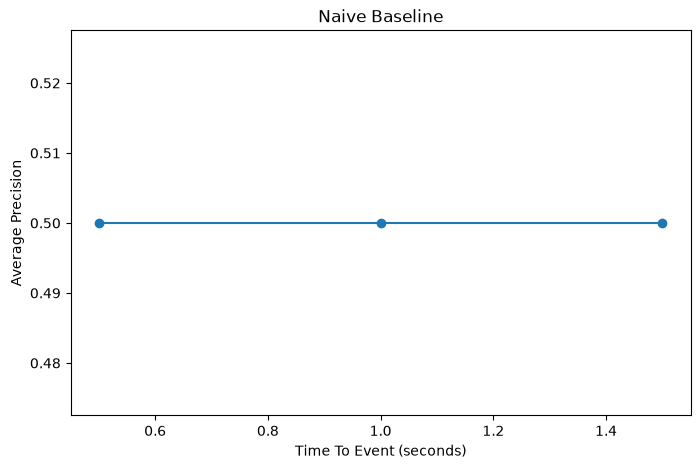

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    naive_results_df["tte"],
    naive_results_df["AP"],
    marker="o"
)

plt.xlabel("Time To Event (seconds)")
plt.ylabel("Average Precision")
plt.title("Naive Baseline")

plt.show()

# Part D — Optical Flow Baseline

The first real computer-vision baseline uses optical flow.

Optical flow estimates apparent motion between consecutive frames.

For every pair of frames:

`Frame t → Frame t+1`

we calculate a flow field.

The flow field contains:

- horizontal motion
- vertical motion

From these values we calculate simple motion statistics.

The goal is not to build a complicated handcrafted system.

Instead, we ask:

> How much collision-prediction information can be obtained from
> relatively simple motion cues?

## 19. Read sampled frames

This function uses the clip metadata generated earlier.

It reads exactly `NUM_FRAMES` frames between the clip start and clip
end.

The frames are returned in temporal order.

In [25]:
def read_clip_frames(
    video_path,
    start_time,
    end_time,
    num_frames=16
):
    cap = cv2.VideoCapture(
        str(video_path)
    )
    
    fps = cap.get(
        cv2.CAP_PROP_FPS
    )
    
    frame_count = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )
    
    start_frame = max(
        0,
        int(start_time * fps)
    )
    
    end_frame = min(
        frame_count - 1,
        int(end_time * fps)
    )
    
    frame_numbers = np.linspace(
        start_frame,
        end_frame,
        num_frames
    ).astype(int)
    
    frames = []
    
    for frame_number in frame_numbers:
        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_number
        )
        
        success, frame = cap.read()
        
        if success:
            frame_gray = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2GRAY
            )
            
            frames.append(
                frame_gray
            )
    
    cap.release()
    
    return frames

## 20. Calculate optical flow

We use the Farneback optical-flow algorithm available in OpenCV.

For each consecutive pair of frames:

`Frame t → Frame t+1`

we obtain a two-dimensional motion vector at each pixel.

The vector contains:

`dx` = horizontal motion

`dy` = vertical motion

The magnitude is:

`sqrt(dx² + dy²)`

In [34]:
def calculate_optical_flow_features(
    frames
):
    pair_features = []
    
    for i in range(
        len(frames) - 1
    ):
        previous_frame = frames[i]
        current_frame = frames[i + 1]
        
        flow = cv2.calcOpticalFlowFarneback(
            previous_frame,
            current_frame,
            None,
            0.5,
            3,
            15,
            3,
            5,
            1.2,
            0
        )
        
        dx = flow[:, :, 0]
        dy = flow[:, :, 1]
        
        magnitude = np.sqrt(
            dx ** 2 + dy ** 2
        )
        
        pair_features.append([
            np.mean(dx),
            np.std(dx),
            np.mean(dy),
            np.std(dy),
            np.mean(magnitude),
            np.std(magnitude),
            np.max(magnitude)
        ])
    
    return np.array(pair_features)

## 21. Test optical flow on one clip

Before processing the dataset, we test the calculation on one
validation clip.

This is deliberately done before large-scale feature extraction so
that problems can be detected early.

In [35]:
sample_clip = val_clips.iloc[0]

sample_video_id = int(
    sample_clip["id"]
)

sample_video_path = (
    TRAIN_DIR /
    f"{sample_video_id:05d}.mp4"
)

sample_frames = read_clip_frames(
    sample_video_path,
    sample_clip["clip_start"],
    sample_clip["clip_end"],
    NUM_FRAMES
)

print("Number of frames:", len(sample_frames))

Number of frames: 16


In [36]:
sample_flow_features = (
    calculate_optical_flow_features(
        sample_frames
    )
)

print(
    "Optical flow feature shape:",
    sample_flow_features.shape
)

Optical flow feature shape: (15, 7)


## 22. Aggregate motion over time

The optical-flow function gives seven statistics for every consecutive
frame pair.

We need one fixed-length feature vector for the entire clip.

For each of the seven motion statistics we calculate:

- mean over time
- standard deviation over time
- maximum over time

This produces:

`7 × 3 = 21 features`

for every clip.

In [37]:
def aggregate_flow_features(
    flow_features
):
    mean_features = np.mean(
        flow_features,
        axis=0
    )
    
    std_features = np.std(
        flow_features,
        axis=0
    )
    
    max_features = np.max(
        flow_features,
        axis=0
    )
    
    features = np.concatenate([
        mean_features,
        std_features,
        max_features
    ])
    
    return features

## 23. Create a complete optical-flow feature extractor

This function combines:

1. Video loading
2. Frame sampling
3. Optical-flow calculation
4. Temporal aggregation

In [38]:
def extract_motion_features(
    video_path,
    clip_start,
    clip_end,
    num_frames=16
):
    frames = read_clip_frames(
        video_path,
        clip_start,
        clip_end,
        num_frames
    )
    
    if len(frames) < 2:
        return None
    
    flow_features = (
        calculate_optical_flow_features(
            frames
        )
    )
    
    if len(flow_features) == 0:
        return None
    
    features = (
        aggregate_flow_features(
            flow_features
        )
    )
    
    return features

## 24. Extract optical-flow features for the training set

We now process the clips.

This may take some time because every clip requires:

- video decoding,
- frame extraction,
- optical-flow calculation.

We process one clip at a time rather than loading the entire dataset
into memory.

In [39]:
def build_feature_matrix(
    clip_df
):
    features = []
    labels = []
    metadata = []
    
    for index, row in clip_df.iterrows():
        video_id = int(row["id"])
        
        video_path = (
            TRAIN_DIR /
            f"{video_id:05d}.mp4"
        )
        
        motion_features = (
            extract_motion_features(
                video_path,
                row["clip_start"],
                row["clip_end"],
                NUM_FRAMES
            )
        )
        
        if motion_features is None:
            print(
                "Could not process clip:",
                index
            )
            continue
        
        features.append(
            motion_features
        )
        
        labels.append(
            int(row["target"])
        )
        
        metadata.append({
            "id": video_id,
            "tte": row["tte"]
        })
    
    return (
        np.array(features),
        np.array(labels),
        pd.DataFrame(metadata)
    )

In [40]:
test_clip = val_clips.iloc[0]

test_video_id = int(test_clip["id"])

test_video_path = (
    TRAIN_DIR /
    f"{test_video_id:05d}.mp4"
)

test_frames = read_clip_frames(
    test_video_path,
    test_clip["clip_start"],
    test_clip["clip_end"],
    NUM_FRAMES
)

print("Video ID:", test_video_id)
print("Number of frames:", len(test_frames))

Video ID: 1339
Number of frames: 16


In [41]:
test_flow_features = calculate_optical_flow_features(
    test_frames
)

print(
    "Optical flow feature shape:",
    test_flow_features.shape
)

Optical flow feature shape: (15, 7)


In [42]:
test_aggregated_features = aggregate_flow_features(
    test_flow_features
)

print(
    "Final feature vector shape:",
    test_aggregated_features.shape
)

Final feature vector shape: (21,)


## 25. Build optical-flow training features

We build a separate feature matrix for each TTE.

This makes the experiments easy to understand and keeps each TTE
condition independent.

In [43]:
train_flow_data = {}

for tte in TTE_VALUES:
    print(
        f"\nProcessing training TTE = {tte:.1f}s"
    )
    
    tte_clips = train_clips[
        train_clips["tte"] == tte
    ]
    
    X_train, y_train, metadata_train = (
        build_feature_matrix(
            tte_clips
        )
    )
    
    train_flow_data[tte] = {
        "X": X_train,
        "y": y_train,
        "metadata": metadata_train
    }
    
    print(
        "Feature matrix shape:",
        X_train.shape
    )


Processing training TTE = 0.5s
Feature matrix shape: (1200, 21)

Processing training TTE = 1.0s
Feature matrix shape: (1200, 21)

Processing training TTE = 1.5s
Feature matrix shape: (1199, 21)


In [44]:
for tte in TTE_VALUES:
    np.save(
        PROCESSED_DIR / f"X_train_flow_tte_{tte}.npy",
        train_flow_data[tte]["X"]
    )
    
    np.save(
        PROCESSED_DIR / f"y_train_flow_tte_{tte}.npy",
        train_flow_data[tte]["y"]
    )

print("Saved training optical-flow features.")

Saved training optical-flow features.


## 26. Build optical-flow validation features

We repeat exactly the same process for validation.

No training information is used when calculating validation features.

In [45]:
val_flow_data = {}

for tte in TTE_VALUES:
    print(
        f"\nProcessing validation TTE = {tte:.1f}s"
    )
    
    tte_clips = val_clips[
        val_clips["tte"] == tte
    ]
    
    X_val, y_val, metadata_val = (
        build_feature_matrix(
            tte_clips
        )
    )
    
    val_flow_data[tte] = {
        "X": X_val,
        "y": y_val,
        "metadata": metadata_val
    }
    
    print(
        "Feature matrix shape:",
        X_val.shape
    )


Processing validation TTE = 0.5s
Feature matrix shape: (300, 21)

Processing validation TTE = 1.0s
Feature matrix shape: (300, 21)

Processing validation TTE = 1.5s
Feature matrix shape: (300, 21)


In [46]:
for tte in TTE_VALUES:
    np.save(
        PROCESSED_DIR / f"X_val_flow_tte_{tte}.npy",
        val_flow_data[tte]["X"]
    )
    
    np.save(
        PROCESSED_DIR / f"y_val_flow_tte_{tte}.npy",
        val_flow_data[tte]["y"]
    )

print("Saved validation optical-flow features.")

Saved validation optical-flow features.


## 27. Train the optical-flow classifier

We use logistic regression as the classifier.

The optical-flow features are the input.

The target is:

`0 = negative`

`1 = positive`

The classifier is deliberately simple.

This keeps the baseline focused on the information contained in the
motion representation rather than introducing a complicated classifier.

In [47]:
optical_flow_results = []

optical_flow_models = {}

for tte in TTE_VALUES:
    X_train = train_flow_data[tte]["X"]
    y_train = train_flow_data[tte]["y"]
    
    X_val = val_flow_data[tte]["X"]
    y_val = val_flow_data[tte]["y"]
    
    model = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_SEED
    )
    
    model.fit(
        X_train,
        y_train
    )
    
    y_probability = model.predict_proba(
        X_val
    )[:, 1]
    
    metrics = evaluate_predictions(
        y_val,
        y_probability
    )
    
    optical_flow_results.append({
        "model": "optical_flow",
        "tte": tte,
        **metrics
    })
    
    optical_flow_models[tte] = model

## 28. Optical-flow baseline results

In [48]:
optical_flow_results_df = pd.DataFrame(
    optical_flow_results
)

optical_flow_results_df

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,optical_flow,0.5,0.582072,0.586933,0.559055,0.473333,0.512635
1,optical_flow,1.0,0.569201,0.592667,0.545455,0.480000,0.510638
2,optical_flow,1.5,0.568029,0.575956,0.554745,0.506667,0.529617


## 29. Combine baseline results

In [49]:
baseline_results_df = pd.concat(
    [
        naive_results_df,
        optical_flow_results_df
    ],
    ignore_index=True
)

baseline_results_df

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667
1,naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667
2,naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667
3,optical_flow,0.5,0.582072,0.586933,0.559055,0.473333,0.512635
4,optical_flow,1.0,0.569201,0.592667,0.545455,0.480000,0.510638
5,optical_flow,1.5,0.568029,0.575956,0.554745,0.506667,0.529617


## 30. Compare Average Precision

The main comparison at this stage is Average Precision as a function
of TTE.

The naive baseline provides the reference level.

The optical-flow model tests whether simple motion cues provide
additional predictive information.

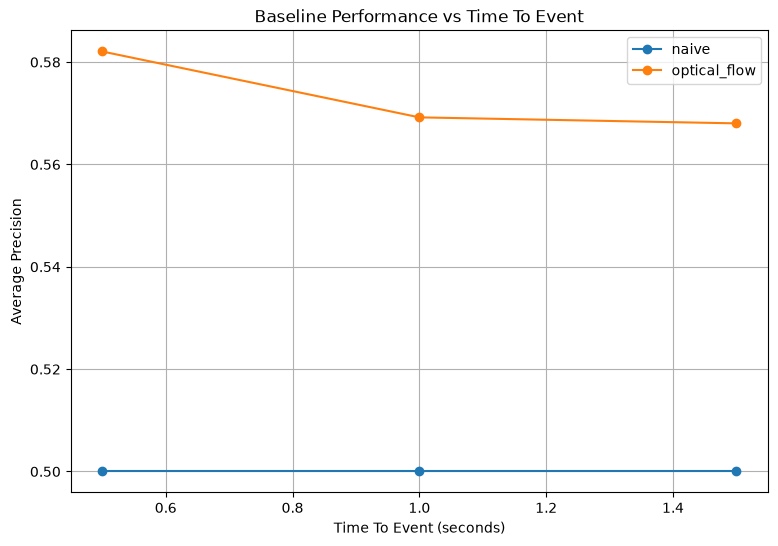

In [50]:
plt.figure(figsize=(9, 6))

for model_name in baseline_results_df["model"].unique():
    model_results = baseline_results_df[
        baseline_results_df["model"] == model_name
    ]
    
    plt.plot(
        model_results["tte"],
        model_results["AP"],
        marker="o",
        label=model_name
    )

plt.xlabel("Time To Event (seconds)")
plt.ylabel("Average Precision")
plt.title("Baseline Performance vs Time To Event")
plt.legend()
plt.grid(True)

plt.show()

In [53]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_SEED
    ))
])

## 31. Optical-flow confusion matrices

A confusion matrix gives a threshold-based view of the classifier.

The probability threshold is:

`0.5`

The confusion matrix contains:

- True Negatives
- False Positives
- False Negatives
- True Positives

We inspect each TTE separately.

In [51]:
for tte in TTE_VALUES:
    X_val = val_flow_data[tte]["X"]
    y_val = val_flow_data[tte]["y"]
    
    model = optical_flow_models[tte]
    
    y_prediction = model.predict(
        X_val
    )
    
    cm = confusion_matrix(
        y_val,
        y_prediction
    )
    
    print(f"\nTTE = {tte:.1f}s")
    print(cm)


TTE = 0.5s
[[94 56]
 [79 71]]

TTE = 1.0s
[[90 60]
 [78 72]]

TTE = 1.5s
[[89 61]
 [74 76]]


## 32. Save baseline results

The numerical results are saved so they can later be incorporated into
the final comparison and report.

The raw video data is not saved here.

In [54]:
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.joinpath(
    "baseline_results.csv"
)

baseline_results_df.to_csv(
    RESULTS_DIR / "baseline_results.csv",
    index=False
)

print("Saved baseline results.")

Saved baseline results.


# Notebook 4 Summary

This notebook established the first complete experimental pipeline.

## Sampling

- Fixed video-level train/validation split
- 2-second observation window
- 16 sampled frames
- TTE = 0.5, 1.0, 1.5 seconds
- No post-prediction frames
- Reproducible negative sampling
- Positive and negative prediction-time distributions approximately
  matched

## Baseline

A naive probability baseline was established.

## Classical model

Optical flow was calculated between consecutive frames.

Seven motion statistics were calculated for each frame pair:

- mean horizontal flow
- standard deviation of horizontal flow
- mean vertical flow
- standard deviation of vertical flow
- mean flow magnitude
- standard deviation of flow magnitude
- maximum flow magnitude

These were aggregated over time to produce 21 features per clip.

A logistic-regression classifier was then trained using these features.

## Evaluation

The primary metric is:

**Average Precision (AP)**

Additional metrics:

- ROC-AUC
- precision
- recall
- F1
- confusion matrix

## Saved files

The notebook produces:

`data/processed/train_clips.csv`

`data/processed/val_clips.csv`

`results/baseline_results.csv`

## Next step

The next stage is the learned temporal model:

Video frames
→ CNN feature extraction
→ temporal sequence
→ LSTM/GRU
→ collision probability

The learned model must use the same clip indices and validation clips
established in this notebook.

In [55]:
train_flow_saved = {}
val_flow_saved = {}

for tte in TTE_VALUES:
    X_train = np.load(
        PROCESSED_DIR / f"X_train_flow_tte_{tte}.npy"
    )
    
    y_train = np.load(
        PROCESSED_DIR / f"y_train_flow_tte_{tte}.npy"
    )
    
    X_val = np.load(
        PROCESSED_DIR / f"X_val_flow_tte_{tte}.npy"
    )
    
    y_val = np.load(
        PROCESSED_DIR / f"y_val_flow_tte_{tte}.npy"
    )
    
    train_flow_saved[tte] = {
        "X": X_train,
        "y": y_train
    }
    
    val_flow_saved[tte] = {
        "X": X_val,
        "y": y_val
    }
    
    print(
        f"TTE {tte:.1f}s:"
    )
    print(
        "  Training:",
        X_train.shape,
        y_train.shape
    )
    print(
        "  Validation:",
        X_val.shape,
        y_val.shape
    )

TTE 0.5s:
  Training: (1200, 21) (1200,)
  Validation: (300, 21) (300,)
TTE 1.0s:
  Training: (1200, 21) (1200,)
  Validation: (300, 21) (300,)
TTE 1.5s:
  Training: (1199, 21) (1199,)
  Validation: (300, 21) (300,)


In [56]:
scaled_flow_results = []

scaled_flow_models = {}

for tte in TTE_VALUES:
    X_train = train_flow_saved[tte]["X"]
    y_train = train_flow_saved[tte]["y"]
    
    X_val = val_flow_saved[tte]["X"]
    y_val = val_flow_saved[tte]["y"]
    
    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_SEED
            )
        )
    ])
    
    model.fit(
        X_train,
        y_train
    )
    
    y_probability = model.predict_proba(
        X_val
    )[:, 1]
    
    metrics = evaluate_predictions(
        y_val,
        y_probability
    )
    
    scaled_flow_results.append({
        "model": "optical_flow_scaled",
        "tte": tte,
        **metrics
    })
    
    scaled_flow_models[tte] = model

In [57]:
scaled_flow_results_df = pd.DataFrame(
    scaled_flow_results
)

scaled_flow_results_df

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,optical_flow_scaled,0.5,0.574508,0.588711,0.543307,0.460000,0.498195
1,optical_flow_scaled,1.0,0.575785,0.591511,0.530303,0.466667,0.496454
2,optical_flow_scaled,1.5,0.568349,0.573911,0.544118,0.493333,0.517483


In [58]:
all_baseline_results = pd.concat(
    [
        naive_results_df,
        optical_flow_results_df,
        scaled_flow_results_df
    ],
    ignore_index=True
)

all_baseline_results

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667
1,naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667
2,naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667
3,optical_flow,0.5,0.582072,0.586933,0.559055,0.473333,0.512635
4,optical_flow,1.0,0.569201,0.592667,0.545455,0.480000,0.510638
5,optical_flow,1.5,0.568029,0.575956,0.554745,0.506667,0.529617
6,optical_flow_scaled,0.5,0.574508,0.588711,0.543307,0.460000,0.498195
7,optical_flow_scaled,1.0,0.575785,0.591511,0.530303,0.466667,0.496454
8,optical_flow_scaled,1.5,0.568349,0.573911,0.544118,0.493333,0.517483


##  Final Baseline Results

We tested two versions of the optical-flow classifier:

1. Original optical-flow features with logistic regression.
2. Standardised optical-flow features with logistic regression.

The standardised version is used as the final optical-flow baseline.

We therefore keep only:

- the naive baseline
- the standardised optical-flow baseline

for the final comparison.

In [59]:
final_baseline_results = pd.concat(
    [
        naive_results_df,
        scaled_flow_results_df
    ],
    ignore_index=True
)

final_baseline_results

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667
1,naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667
2,naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667
3,optical_flow_scaled,0.5,0.574508,0.588711,0.543307,0.460000,0.498195
4,optical_flow_scaled,1.0,0.575785,0.591511,0.530303,0.466667,0.496454
5,optical_flow_scaled,1.5,0.568349,0.573911,0.544118,0.493333,0.517483


## Rename Models for Presentation

The internal model name `optical_flow_scaled` describes the implementation,
but `Optical Flow` is clearer when presenting the results.

The underlying model remains the standardised optical-flow baseline.

In [60]:
plot_results = final_baseline_results.copy()

plot_results["model"] = plot_results["model"].replace({
    "naive": "Naive",
    "optical_flow_scaled": "Optical Flow"
})

plot_results

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,Naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667
1,Naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667
2,Naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667
3,Optical Flow,0.5,0.574508,0.588711,0.543307,0.460000,0.498195
4,Optical Flow,1.0,0.575785,0.591511,0.530303,0.466667,0.496454
5,Optical Flow,1.5,0.568349,0.573911,0.544118,0.493333,0.517483


## Baseline Average Precision Across TTE

Average Precision (AP) is the primary evaluation metric for this project.

This plot shows how the naive and optical-flow baselines perform at each
prediction horizon.

A higher AP indicates better ranking of positive collision clips above
negative clips.

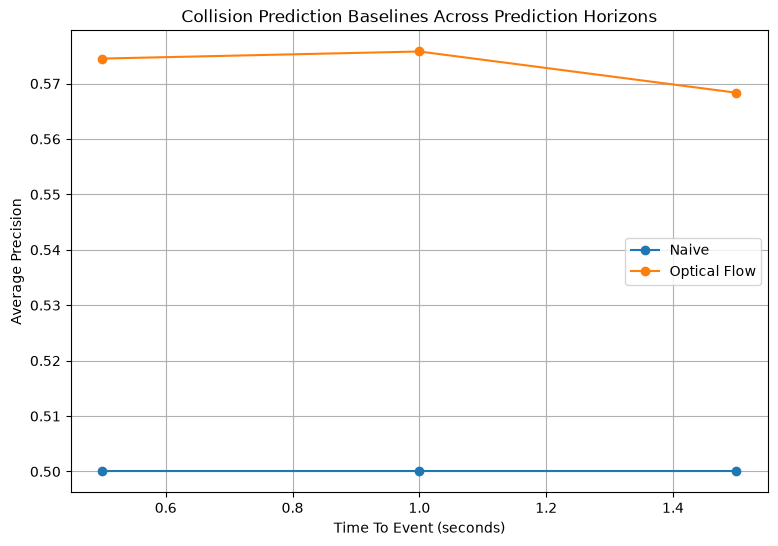

In [61]:
plt.figure(figsize=(9, 6))

for model_name in plot_results["model"].unique():
    model_results = plot_results[
        plot_results["model"] == model_name
    ]

    plt.plot(
        model_results["tte"],
        model_results["AP"],
        marker="o",
        label=model_name
    )

plt.xlabel("Time To Event (seconds)")
plt.ylabel("Average Precision")
plt.title(
    "Collision Prediction Baselines Across Prediction Horizons"
)

plt.legend()
plt.grid(True)

plt.show()

## 16. Compare Baseline Metrics

The table below provides the complete set of evaluation metrics for the
final baseline models.

AP and ROC-AUC evaluate the ranking quality of the predicted probabilities.

Precision, Recall and F1 depend on a classification threshold of 0.5 and
are therefore interpreted as secondary metrics.

In [62]:
final_baseline_results[
    [
        "model",
        "tte",
        "AP",
        "ROC_AUC",
        "Precision",
        "Recall",
        "F1"
    ]
]

,model,tte,AP,ROC_AUC,Precision,Recall,F1
0,naive,0.5,0.500000,0.500000,0.500000,1.000000,0.666667
1,naive,1.0,0.500000,0.500000,0.500000,1.000000,0.666667
2,naive,1.5,0.500000,0.500000,0.500000,1.000000,0.666667
3,optical_flow_scaled,0.5,0.574508,0.588711,0.543307,0.460000,0.498195
4,optical_flow_scaled,1.0,0.575785,0.591511,0.530303,0.466667,0.496454
5,optical_flow_scaled,1.5,0.568349,0.573911,0.544118,0.493333,0.517483


## 17. Baseline Results

The final baseline results are:

| Model | TTE | AP | ROC-AUC | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Naive | 0.5 s | 0.5000 | 0.5000 | 0.5000 | 1.0000 | 0.6667 |
| Naive | 1.0 s | 0.5000 | 0.5000 | 0.5000 | 1.0000 | 0.6667 |
| Naive | 1.5 s | 0.5000 | 0.5000 | 0.5000 | 1.0000 | 0.6667 |
| Optical Flow | 0.5 s | 0.5745 | 0.5887 | 0.5433 | 0.4600 | 0.4982 |
| Optical Flow | 1.0 s | 0.5758 | 0.5915 | 0.5303 | 0.4667 | 0.4965 |
| Optical Flow | 1.5 s | 0.5683 | 0.5739 | 0.5441 | 0.4933 | 0.5175 |

The optical-flow baseline produces AP and ROC-AUC values above the naive
reference at all three evaluated prediction horizons.

The results provide a classical motion-based reference point for the
learned temporal model.

## Confusion Matrices

The confusion matrix shows the classification behaviour of the optical-flow
model at the default probability threshold of 0.5.

Because confusion matrices depend on this threshold, they are treated as
secondary analysis rather than the primary measure of performance.

In [63]:
for tte in TTE_VALUES:

    X_val = val_flow_saved[tte]["X"]
    y_val = val_flow_saved[tte]["y"]

    model = scaled_flow_models[tte]

    y_prediction = model.predict(
        X_val
    )

    cm = confusion_matrix(
        y_val,
        y_prediction
    )

    print(f"\nTTE = {tte:.1f}s")
    print(cm)


TTE = 0.5s
[[92 58]
 [81 69]]

TTE = 1.0s
[[88 62]
 [80 70]]

TTE = 1.5s
[[88 62]
 [76 74]]


## Visualise Confusion Matrices

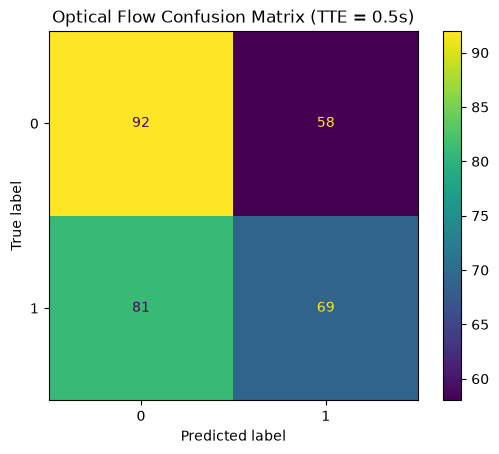

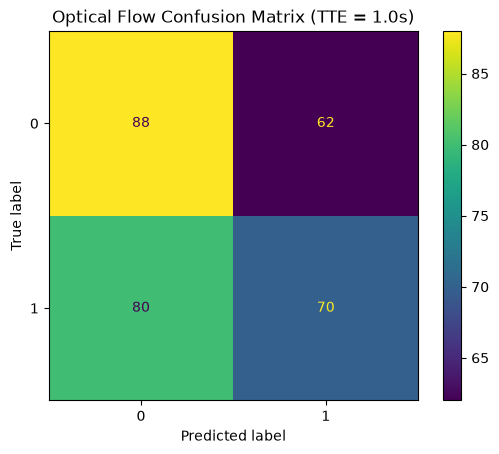

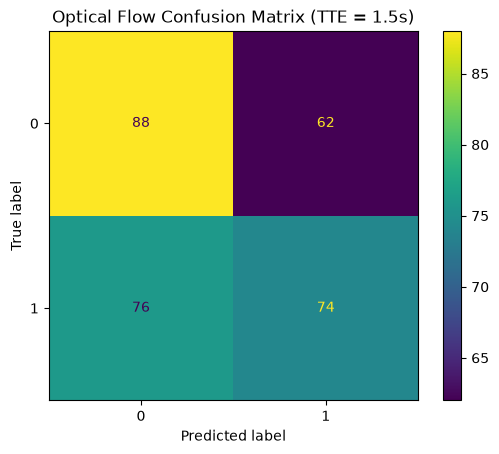

In [64]:
for tte in TTE_VALUES:

    X_val = val_flow_saved[tte]["X"]
    y_val = val_flow_saved[tte]["y"]

    model = scaled_flow_models[tte]

    y_prediction = model.predict(
        X_val
    )

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_prediction
    )

    plt.title(
        f"Optical Flow Confusion Matrix "
        f"(TTE = {tte:.1f}s)"
    )

    plt.show()

## 20. Save Final Baseline Results

The final baseline table is saved so that later notebooks and the final
report can use the same results without rerunning the experiment.

In [65]:
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_baseline_results.to_csv(
    RESULTS_DIR / "baseline_results.csv",
    index=False
)

print("Saved final baseline results.")

Saved final baseline results.


## 21. Baseline Conclusions

The baseline experiment established the following:

- The naive baseline produces AP = 0.50 and ROC-AUC = 0.50.
- Optical-flow features produce performance above the naive reference.
- Optical-flow AP ranges from approximately 0.568 to 0.576 across the
  three prediction horizons.
- The optical-flow baseline therefore provides a measurable classical
  computer-vision reference.
- The same TTE values and validation protocol will be used for the learned
  temporal model.

The main question for the next stage is whether learned visual and temporal
representations can improve upon this classical motion baseline.